In [14]:
!pip install yfinance pandas requests beautifulsoup4 html5lib plotly lxml

In [15]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
from io import StringIO
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [16]:
tesla = yf.Ticker("TSLA")

In [17]:
tesla_data = tesla.history(period="max")

In [18]:
tesla_data.reset_index(inplace=True)
tesla_data.head(5)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [20]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url).text

soup = BeautifulSoup(html_data, "html5lib")

tesla_revenue = pd.DataFrame(columns=["Date", "Revenue"])

for table in soup.find_all("table"):
    header = table.find("th")

    if header and "Tesla Quarterly Revenue" in header.get_text(strip=True):
        for row in table.find_all("tr"):
            columns = row.find_all("td")

            if len(columns) == 2:
                date = columns[0].get_text(strip=True)
                revenue = columns[1].get_text(strip=True)

                revenue = revenue.replace("$", "").replace(",", "")

                if date != "" and revenue != "":
                    tesla_revenue.loc[len(tesla_revenue)] = [date, revenue]

tesla_revenue.dropna(inplace=True)

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
51,2009-09-30,46
52,2009-06-30,27


In [24]:
gme = yf.Ticker("GME")

In [26]:
gme_data = gme.history(period="max")

In [27]:
gme_data.reset_index(inplace=True)
gme_data.head(5)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [40]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

html_data = requests.get(url).text

soup = BeautifulSoup(html_data, "html5lib")

In [41]:
gme_revenue = pd.DataFrame(columns=["Date", "Revenue"])

for table in soup.find_all("table"):
    header = table.find("th")

    if header and "GameStop Quarterly Revenue" in header.get_text(strip=True):
        for row in table.find_all("tr")[1:]:
            columns = row.find_all("td")

            if len(columns) == 2:
                date = columns[0].get_text(strip=True)
                revenue = columns[1].get_text(strip=True)

                revenue = revenue.replace("$", "").replace(",", "")

                if date != "" and revenue != "":
                    gme_revenue.loc[len(gme_revenue)] = [date, revenue]

gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue["Revenue"] != ""]

gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


In [43]:
gme_revenue["Date"] = pd.to_datetime(gme_revenue["Date"])
gme_revenue["Revenue"] = pd.to_numeric(gme_revenue["Revenue"], errors="coerce")

gme_revenue = gme_revenue.dropna()
gme_revenue = gme_revenue.sort_values("Date")

gme_revenue.tail()

,Date,Revenue
4,2019-04-30,1548
3,2019-07-31,1286
2,2019-10-31,1439
1,2020-01-31,2194
0,2020-04-30,1021


In [44]:
tesla_revenue["Date"] = pd.to_datetime(tesla_revenue["Date"])
tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"], errors="coerce")

tesla_revenue = tesla_revenue.dropna()
tesla_revenue = tesla_revenue.sort_values("Date")

tesla_revenue.tail()

,Date,Revenue
4,2021-09-30,13757
3,2021-12-31,17719
2,2022-03-31,18756
1,2022-06-30,16934
0,2022-09-30,21454


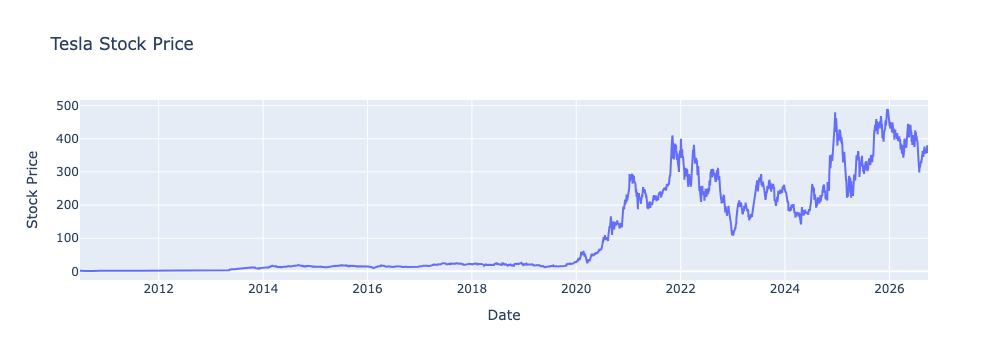

In [45]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=tesla_data["Date"],
    y=tesla_data["Close"],
    mode="lines",
    name="Tesla Stock Price"
))

fig.update_layout(
    title="Tesla Stock Price",
    xaxis_title="Date",
    yaxis_title="Stock Price"
)

fig.show()

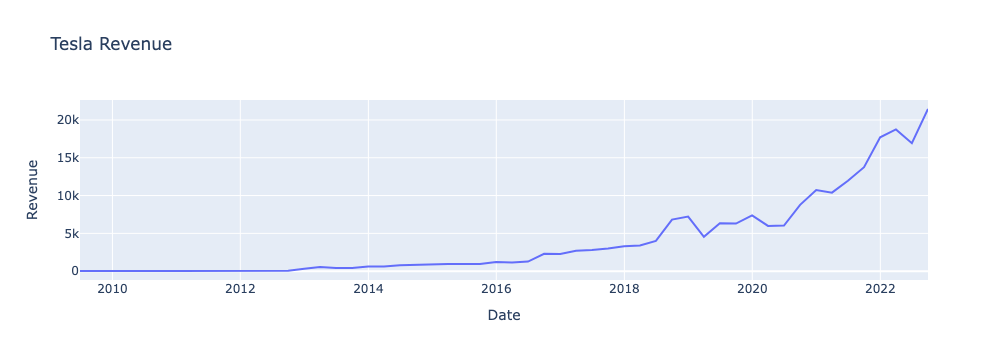

In [46]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=tesla_revenue["Date"],
    y=tesla_revenue["Revenue"],
    mode="lines",
    name="Tesla Revenue"
))

fig.update_layout(
    title="Tesla Revenue",
    xaxis_title="Date",
    yaxis_title="Revenue"
)

fig.show()

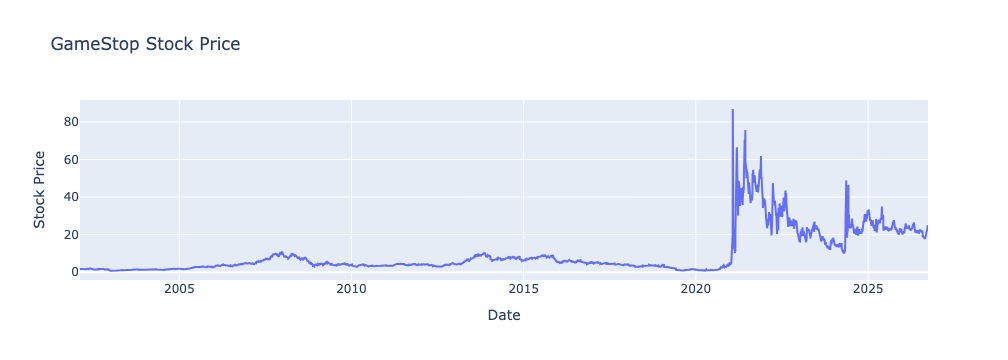

In [47]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=gme_data["Date"],
    y=gme_data["Close"],
    mode="lines",
    name="GameStop Stock Price"
))

fig.update_layout(
    title="GameStop Stock Price",
    xaxis_title="Date",
    yaxis_title="Stock Price"
)

fig.show()

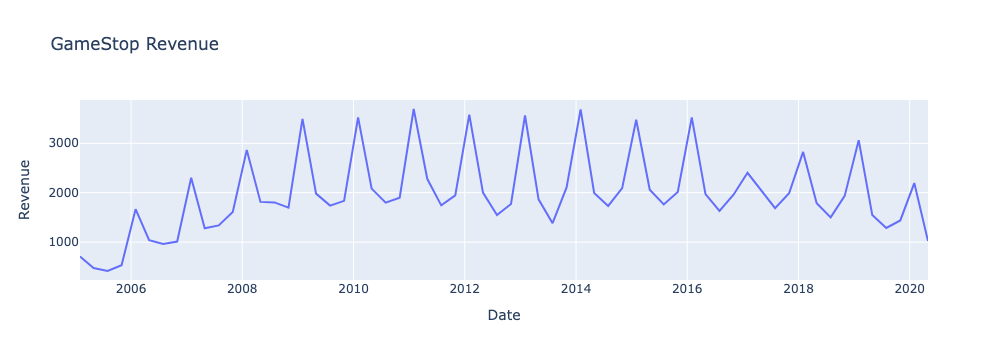

In [48]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=gme_revenue["Date"],
    y=gme_revenue["Revenue"],
    mode="lines",
    name="GameStop Revenue"
))

fig.update_layout(
    title="GameStop Revenue",
    xaxis_title="Date",
    yaxis_title="Revenue"
)

fig.show()